<a href="https://colab.research.google.com/github/dsatishreddy/AugRevolution/blob/main/2026CT05190_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install numpy pandas matplotlib scikit-learn

In [2]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
DATA_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
)

feature_names = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

column_names = ["id", "diagnosis"] + feature_names

df = pd.read_csv(
    DATA_URL,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Number of samples:", len(df))
print("Number of input features:", len(feature_names))

display(df.head())

Dataset loaded successfully!
Number of samples: 569
Number of input features: 30


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
print("Dataset shape:", df.shape)

print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

print("\nFeature statistics:")
display(df[feature_names].describe().T.head(10))

Dataset shape: (569, 32)

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values: 0

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


In [5]:
# Input features; exclude the ID column
X = df[feature_names].to_numpy(dtype=float)

# Target: malignant = 1, benign = 0
y = (df["diagnosis"].to_numpy() == "M").astype(int)

# Split into training and testing datasets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit scaler only on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Training samples: 455
Testing samples: 114
Training features: 30
Testing features: 30


In [7]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def binary_cross_entropy(y_true, probabilities):
    eps = 1e-12

    probabilities = np.clip(
        probabilities, eps, 1 - eps
    )

    loss = -np.mean(
        y_true * np.log(probabilities)
        + (1 - y_true) * np.log(1 - probabilities)
    )

    return loss


def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "precision": float(
            precision_score(
                y_true, y_pred, zero_division=0
            )
        ),
        "recall": float(
            recall_score(
                y_true, y_pred, zero_division=0
            )
        ),
        "f1_score": float(
            f1_score(
                y_true, y_pred, zero_division=0
            )
        )
    }

In [8]:
class LogisticRegressionScratch:

    def __init__(
        self,
        learning_rate=0.05,
        n_iterations=2000
    ):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.loss_history = []
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        y = y.reshape(-1, 1)

        for _ in range(self.n_iterations):

            # Forward propagation
            linear_output = (
                X @ self.weights.reshape(-1, 1)
                + self.bias
            )

            probabilities = sigmoid(linear_output)

            # Calculate loss
            loss = binary_cross_entropy(
                y, probabilities
            )

            self.loss_history.append(float(loss))

            # Calculate gradients
            dw = (
                X.T @ (probabilities - y)
            ) / n_samples

            db = np.mean(probabilities - y)

            # Update weights and bias
            self.weights -= self.lr * dw.ravel()
            self.bias -= self.lr * db

        return self

    def predict_proba(self, X):

        linear_output = (
            X @ self.weights.reshape(-1, 1)
            + self.bias
        )

        return sigmoid(linear_output).ravel()

    def predict(self, X):

        probabilities = self.predict_proba(X)

        return (probabilities >= 0.5).astype(int)

In [9]:
baseline = LogisticRegressionScratch(
    learning_rate=0.05,
    n_iterations=2000
)

start_time = time.perf_counter()

baseline.fit(X_train, y_train)

baseline_time = time.perf_counter() - start_time

baseline_pred = baseline.predict(X_test)

baseline_metrics = calculate_metrics(
    y_test, baseline_pred
)

print("BASELINE MODEL RESULTS")
print("----------------------")

print("Training time:",
      round(baseline_time, 4), "seconds")

print("Final training loss:",
      round(baseline.loss_history[-1], 6))

print(json.dumps(baseline_metrics, indent=2))

print("\nClassification report:")

print(classification_report(
    y_test,
    baseline_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

BASELINE MODEL RESULTS
----------------------
Training time: 0.8797 seconds
Final training loss: 0.060838
{
  "accuracy": 0.9824561403508771,
  "precision": 1.0,
  "recall": 0.9523809523809523,
  "f1_score": 0.975609756097561
}

Classification report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [10]:
class MLP:

    def __init__(
        self,
        architecture,
        learning_rate=0.01,
        n_iterations=300,
        batch_size=32,
        seed=42
    ):
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.batch_size = batch_size
        self.seed = seed

        self.weights = []
        self.biases = []
        self.loss_history = []

    def initialize_parameters(self):

        rng = np.random.default_rng(self.seed)

        self.weights = []
        self.biases = []

        for i in range(1, len(self.architecture)):

            fan_in = self.architecture[i - 1]
            fan_out = self.architecture[i]

            # He initialization for hidden layers
            if i < len(self.architecture) - 1:
                W = (
                    rng.standard_normal((fan_in, fan_out))
                    * np.sqrt(2.0 / fan_in)
                )
            else:
                W = (
                    rng.standard_normal((fan_in, fan_out))
                    * np.sqrt(1.0 / fan_in)
                )

            b = np.zeros((1, fan_out))

            self.weights.append(W)
            self.biases.append(b)

    def relu(self, z):
        return np.maximum(0, z)

    def relu_derivative(self, z):
        return (z > 0).astype(float)

    def forward_propagation(self, X):

        activations = [X]
        z_values = []

        A = X

        for i in range(len(self.weights)):

            Z = A @ self.weights[i] + self.biases[i]

            z_values.append(Z)

            # Output layer uses sigmoid
            if i == len(self.weights) - 1:
                A = sigmoid(Z)
            else:
                A = self.relu(Z)

            activations.append(A)

        cache = {
            "activations": activations,
            "z_values": z_values
        }

        return activations[-1], cache

    def backward_propagation(self, y, cache):

        y = y.reshape(-1, 1)

        activations = cache["activations"]
        z_values = cache["z_values"]

        n_samples = y.shape[0]

        # Derivative for sigmoid + binary cross-entropy
        dZ = activations[-1] - y

        dW = [None] * len(self.weights)
        db = [None] * len(self.biases)

        for i in reversed(range(len(self.weights))):

            A_previous = activations[i]

            dW[i] = (
                A_previous.T @ dZ
            ) / n_samples

            db[i] = np.mean(
                dZ, axis=0, keepdims=True
            )

            if i > 0:

                dA_previous = (
                    dZ @ self.weights[i].T
                )

                dZ = (
                    dA_previous
                    * self.relu_derivative(z_values[i - 1])
                )

        return dW, db

    def fit(self, X, y):

        self.initialize_parameters()
        self.loss_history = []

        rng = np.random.default_rng(self.seed)

        n_samples = X.shape[0]
        y_column = y.reshape(-1, 1)

        for epoch in range(self.n_iterations):

            # Shuffle the training dataset
            indices = rng.permutation(n_samples)

            X_shuffled = X[indices]
            y_shuffled = y_column[indices]

            # Mini-batch gradient descent
            for start in range(
                0, n_samples, self.batch_size
            ):

                end = start + self.batch_size

                X_batch = X_shuffled[start:end]
                y_batch = y_shuffled[start:end]

                _, cache = self.forward_propagation(
                    X_batch
                )

                dW, db = self.backward_propagation(
                    y_batch, cache
                )

                # Update parameters
                for i in range(len(self.weights)):

                    self.weights[i] -= self.lr * dW[i]
                    self.biases[i] -= self.lr * db[i]

            # Record full training loss after each epoch
            probabilities, _ = self.forward_propagation(X)

            loss = binary_cross_entropy(
                y, probabilities.ravel()
            )

            self.loss_history.append(float(loss))

        return self

    def predict_proba(self, X):

        probabilities, _ = self.forward_propagation(X)

        return probabilities.ravel()

    def predict(self, X):

        probabilities = self.predict_proba(X)

        return (probabilities >= 0.5).astype(int)

In [11]:
mlp = MLP(
    architecture=[30, 16, 8, 1],
    learning_rate=0.01,
    n_iterations=300,
    batch_size=32,
    seed=42
)

start_time = time.perf_counter()

mlp.fit(X_train, y_train)

mlp_time = time.perf_counter() - start_time

mlp_pred = mlp.predict(X_test)

mlp_metrics = calculate_metrics(
    y_test, mlp_pred
)

print("MLP MODEL RESULTS")
print("-----------------")

print("Architecture:", mlp.architecture)

print("Training time:",
      round(mlp_time, 4), "seconds")

print("Final training loss:",
      round(mlp.loss_history[-1], 6))

print(json.dumps(mlp_metrics, indent=2))

print("\nClassification report:")

print(classification_report(
    y_test,
    mlp_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

MLP MODEL RESULTS
-----------------
Architecture: [30, 16, 8, 1]
Training time: 2.5083 seconds
Final training loss: 0.032442
{
  "accuracy": 0.9736842105263158,
  "precision": 1.0,
  "recall": 0.9285714285714286,
  "f1_score": 0.9629629629629629
}

Classification report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



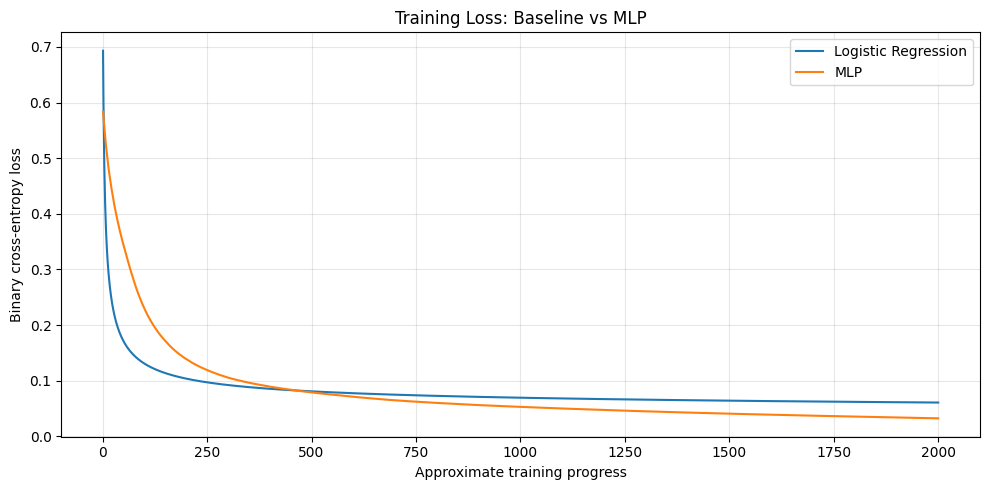

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(baseline.loss_history) + 1),
    baseline.loss_history,
    label="Logistic Regression"
)

# Map MLP epochs to a comparable progress axis
mlp_progress = np.linspace(
    1, len(baseline.loss_history),
    len(mlp.loss_history)
)

plt.plot(
    mlp_progress,
    mlp.loss_history,
    label="MLP"
)

plt.xlabel("Approximate training progress")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training Loss: Baseline vs MLP")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
comparison = pd.DataFrame(
    [baseline_metrics, mlp_metrics],
    index=[
        "Logistic Regression",
        "MLP"
    ]
)

print("Performance comparison:")

display(comparison.round(4))

Performance comparison:


,accuracy,precision,recall,f1_score
Logistic Regression,0.9825,1.0,0.9524,0.9756
MLP,0.9737,1.0,0.9286,0.9630


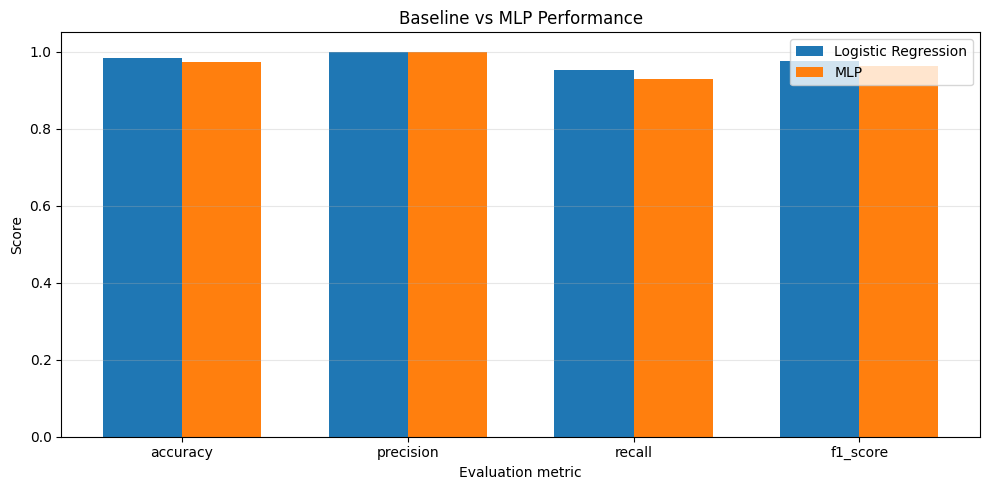

In [14]:
metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    [baseline_metrics[m] for m in metrics],
    width,
    label="Logistic Regression"
)

plt.bar(
    x + width / 2,
    [mlp_metrics[m] for m in metrics],
    width,
    label="MLP"
)

plt.xticks(x, metrics)
plt.ylim(0, 1.05)

plt.xlabel("Evaluation metric")
plt.ylabel("Score")
plt.title("Baseline vs MLP Performance")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

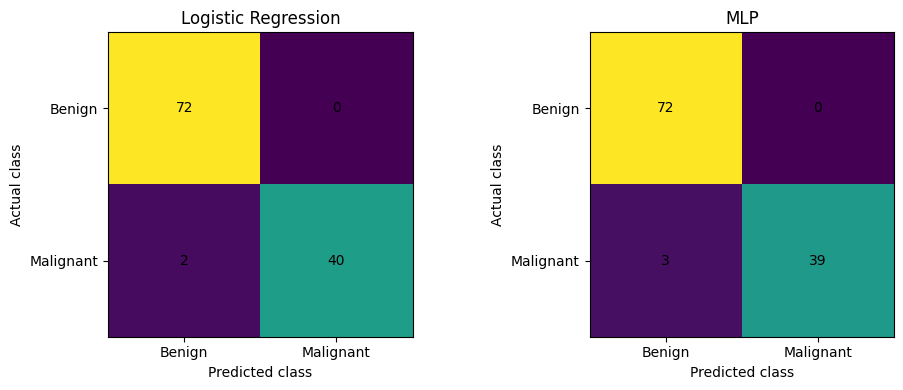

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

models = [
    ("Logistic Regression", baseline_pred),
    ("MLP", mlp_pred)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ax.imshow(cm)

    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    ax.set_xticks(
        [0, 1],
        labels=["Benign", "Malignant"]
    )

    ax.set_yticks(
        [0, 1],
        labels=["Benign", "Malignant"]
    )

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center"
            )

plt.tight_layout()
plt.show()

In [16]:
winner = (
    "MLP"
    if mlp_metrics["recall"] > baseline_metrics["recall"]
    else "Logistic Regression"
    if baseline_metrics["recall"] > mlp_metrics["recall"]
    else "Both models achieved equal recall"
)

recall_difference = abs(
    mlp_metrics["recall"] - baseline_metrics["recall"]
)

analysis = f"""
The primary evaluation metric was recall for the malignant class,
because false negatives are important in medical screening.

Logistic Regression achieved accuracy of
{baseline_metrics['accuracy']:.3f}, precision of
{baseline_metrics['precision']:.3f}, recall of
{baseline_metrics['recall']:.3f}, and F1-score of
{baseline_metrics['f1_score']:.3f}.

The MLP achieved accuracy of {mlp_metrics['accuracy']:.3f},
precision of {mlp_metrics['precision']:.3f}, recall of
{mlp_metrics['recall']:.3f}, and F1-score of
{mlp_metrics['f1_score']:.3f}.

Based on recall, {winner} performed better or achieved an equal
result. The absolute recall difference was {recall_difference:.3f}.
Logistic Regression learns a linear decision boundary, while the
MLP can learn nonlinear relationships through its hidden layers.

Logistic Regression training time was {baseline_time:.3f} seconds,
compared with {mlp_time:.3f} seconds for the MLP. The MLP may require
more computation because it has multiple layers and performs
backpropagation. Actual training times depend on the computer and
software environment. Results are based on one stratified train-test
split and may vary with other splits or initializations.
"""

print(analysis)
print("\nWord count:", len(analysis.split()))


The primary evaluation metric was recall for the malignant class,
because false negatives are important in medical screening.

Logistic Regression achieved accuracy of
0.982, precision of
1.000, recall of
0.952, and F1-score of
0.976.

The MLP achieved accuracy of 0.974,
precision of 1.000, recall of
0.929, and F1-score of
0.963.

Based on recall, Logistic Regression performed better or achieved an equal
result. The absolute recall difference was 0.024.
Logistic Regression learns a linear decision boundary, while the
MLP can learn nonlinear relationships through its hidden layers.

Logistic Regression training time was 0.880 seconds,
compared with 2.508 seconds for the MLP. The MLP may require
more computation because it has multiple layers and performs
backpropagation. Actual training times depend on the computer and
software environment. Results are based on one stratified train-test
split and may vary with other splits or initializations.


Word count: 140


In [17]:
def get_assignment_results():

    return {
        "dataset_name": (
            "Breast Cancer Wisconsin (Diagnostic) - UCI"
        ),

        "n_samples": int(len(df)),

        "n_features": int(len(feature_names)),

        "problem_type": "binary_classification",

        "primary_metric": "recall",

        "baseline_model": {
            "name": "Logistic Regression from scratch",
            "test_accuracy": float(
                baseline_metrics["accuracy"]
            ),
            "test_precision": float(
                baseline_metrics["precision"]
            ),
            "test_recall": float(
                baseline_metrics["recall"]
            ),
            "test_f1_score": float(
                baseline_metrics["f1_score"]
            ),
            "final_training_loss": float(
                baseline.loss_history[-1]
            ),
            "training_time_seconds": float(
                baseline_time
            )
        },

        "mlp_model": {
            "name": "MLP from scratch",
            "architecture": [
                int(v) for v in mlp.architecture
            ],
            "test_accuracy": float(
                mlp_metrics["accuracy"]
            ),
            "test_precision": float(
                mlp_metrics["precision"]
            ),
            "test_recall": float(
                mlp_metrics["recall"]
            ),
            "test_f1_score": float(
                mlp_metrics["f1_score"]
            ),
            "final_training_loss": float(
                mlp.loss_history[-1]
            ),
            "training_time_seconds": float(
                mlp_time
            )
        }
    }


assignment_results = get_assignment_results()

print(json.dumps(assignment_results, indent=2))

{
  "dataset_name": "Breast Cancer Wisconsin (Diagnostic) - UCI",
  "n_samples": 569,
  "n_features": 30,
  "problem_type": "binary_classification",
  "primary_metric": "recall",
  "baseline_model": {
    "name": "Logistic Regression from scratch",
    "test_accuracy": 0.9824561403508771,
    "test_precision": 1.0,
    "test_recall": 0.9523809523809523,
    "test_f1_score": 0.975609756097561,
    "final_training_loss": 0.06083781079506379,
    "training_time_seconds": 0.8796661650000033
  },
  "mlp_model": {
    "name": "MLP from scratch",
    "architecture": [
      30,
      16,
      8,
      1
    ],
    "test_accuracy": 0.9736842105263158,
    "test_precision": 1.0,
    "test_recall": 0.9285714285714286,
    "test_f1_score": 0.9629629629629629,
    "final_training_loss": 0.03244153126822243,
    "training_time_seconds": 2.5082933410000123
  }
}
